
# Golden Shiner MAS 
## Complete Working Notebook

This notebook combines the reusable parts of the previous `past_repo` work with the current design:

- 2D fish physics
- Couzin-style **repulsion + orientation + attraction**
- synchronous `decide()` / `advance()` updating
- reflecting walls
- DataCollector V1
- initial state saved at `t = 0`
- simple result inspection
- optional PyVista 3D visualization of the 2D model
- optional light-dependent speed extension for the next phase

## Important design choice

The scientific model is 2D:

\[
p_i = (x_i,y_i)
\]

PyVista only displays it in 3D:

\[
(x_i,y_i)\rightarrow(x_i,y_i,0)
\]

So visualization does **not** change the physics.



## Where each part comes from

| Current part | Previous project source |
|---|---|
| 2D position, direction, movement, wall bounce | `SingleFish_ContinuousSpace.ipynb` |
| Multiple fish + neighbour detection | `Couzin_Parameters.ipynb` |
| Repulsion + attraction functions | `Couzin_Parameters_maria_attraction.ipynb` |
| `decide()` / `advance()` synchronous structure | `Couzin.py` |
| Three Couzin zones and rule priority | `paper_rules.py` |
| Metrics such as polarization / rotation / NND | `model.py` |
| Later group-size / gradient experiments | `paper_experiments.py` |
| DataCollector V1 | new integrated version |

The old files are useful references, but they are alternative development stages.  
The executable model below is the **single integrated version to use now**.


In [1]:

# Optional installation if your environment does not already have these packages:
import numpy as np
import pandas as pd
import mesa

from mesa.datacollection import DataCollector
from mesa.experimental.continuous_space import (
    ContinuousSpaceAgent,
    ContinuousSpace,
)



# 1. Group metrics

These measurements do not affect fish behaviour.  
They only describe what the group is doing.

We record:

- **Polarization** — alignment
- **Rotation** — milling / circular motion
- **MeanSpeed**
- **MeanNND** — mean nearest-neighbour distance
- **MeanDistanceToCentroid** — group compactness
- **CentroidX / CentroidY**
- **CollectiveState**


In [2]:

def compute_group_metrics(model):
    """Calculate all group-level measurements from the current fish state."""

    fish = list(model.agents)

    if len(fish) == 0:
        return {
            "Polarization": 0.0,
            "Rotation": 0.0,
            "MeanSpeed": 0.0,
            "MeanNND": np.nan,
            "MeanDistanceToCentroid": 0.0,
            "CentroidX": np.nan,
            "CentroidY": np.nan,
            "CollectiveState": "empty",
        }

    # Current state of all fish
    positions = np.array([f.position for f in fish], dtype=float)
    directions = np.array([f.direction for f in fish], dtype=float)
    speeds = np.array([f.speed for f in fish], dtype=float)

    n = len(fish)

    # --------------------------------------------------------
    # CENTROID
    # --------------------------------------------------------
    centroid = np.mean(positions, axis=0)

    # --------------------------------------------------------
    # POLARIZATION
    # --------------------------------------------------------
    # 1 = fish are aligned
    # 0 = headings cancel each other
    mean_direction = np.mean(directions, axis=0)
    polarization = np.linalg.norm(mean_direction)

    # --------------------------------------------------------
    # ROTATION
    # --------------------------------------------------------
    # Vector from group centroid to each fish
    radial_vectors = positions - centroid

    # Distance of each fish from centroid
    radial_distances = np.linalg.norm(radial_vectors, axis=1)

    # Convert radial vectors to unit vectors.
    # A fish exactly at the centroid receives [0, 0].
    unit_radial = np.divide(
        radial_vectors,
        radial_distances[:, None],
        out=np.zeros_like(radial_vectors),
        where=radial_distances[:, None] > 0,
    )

    # 2D cross product between radial direction and fish heading
    rotation_per_fish = (
        unit_radial[:, 0] * directions[:, 1]
        - unit_radial[:, 1] * directions[:, 0]
    )

    rotation = abs(np.mean(rotation_per_fish))

    # --------------------------------------------------------
    # MEAN SPEED
    # --------------------------------------------------------
    mean_speed = np.mean(speeds)

    # --------------------------------------------------------
    # MEAN NEAREST-NEIGHBOUR DISTANCE
    # --------------------------------------------------------
    if n > 1:
        differences = (
            positions[:, None, :]
            - positions[None, :, :]
        )

        distances = np.linalg.norm(differences, axis=2)

        # A fish cannot be its own nearest neighbour
        np.fill_diagonal(distances, np.inf)

        nearest_distances = np.min(distances, axis=1)
        mean_nnd = np.mean(nearest_distances)

    else:
        mean_nnd = np.nan

    # --------------------------------------------------------
    # MEAN DISTANCE TO CENTROID
    # --------------------------------------------------------
    # Smaller value = more compact group
    mean_distance_to_centroid = np.mean(radial_distances)

    # --------------------------------------------------------
    # COLLECTIVE STATE
    # --------------------------------------------------------
    # Literature-inspired exploratory thresholds.
    if polarization > 0.65 and rotation < 0.35:
        collective_state = "polarized"

    elif polarization < 0.35 and rotation > 0.65:
        collective_state = "milling"

    elif polarization < 0.35 and rotation < 0.35:
        collective_state = "swarm"

    else:
        collective_state = "transition"

    return {
        "Polarization": float(polarization),
        "Rotation": float(rotation),
        "MeanSpeed": float(mean_speed),
        "MeanNND": float(mean_nnd) if not np.isnan(mean_nnd) else np.nan,
        "MeanDistanceToCentroid": float(mean_distance_to_centroid),
        "CentroidX": float(centroid[0]),
        "CentroidY": float(centroid[1]),
        "CollectiveState": collective_state,
    }



# 2. Golden Shiner agent

Each fish stores only the state needed for the current model:

\[
(x,y),\quad (d_x,d_y),\quad speed
\]

The social rules use the three Couzin zones:

1. **Repulsion** has priority.
2. If there is no repulsion:
   - orientation,
   - attraction,
   - or their combination.
3. If there are no relevant neighbours, the fish keeps its current direction.


In [3]:

class GoldenShiners(ContinuousSpaceAgent):
    """Golden Shiner with simple Couzin-style local interactions."""

    def __init__(self, model, space, position=(0, 0), speed=1.0):
        super().__init__(space, model)

        # -------------------------
        # CURRENT STATE
        # -------------------------
        self.position = np.array(position, dtype=float)
        self.speed = float(speed)

        # Random initial 2D unit direction
        angle = self.model.rng.uniform(0, 2 * np.pi)

        self.direction = np.array([
            np.cos(angle),
            np.sin(angle),
        ])

        # -------------------------
        # NEXT STATE
        # -------------------------
        # Used for synchronous updating.
        self.next_direction = self.direction.copy()
        self.next_position = self.position.copy()
        self.next_speed = self.speed


    # ========================================================
    # NEIGHBOURS
    # ========================================================

    def get_neighbors(self):
        """Return neighbours inside the maximum social radius."""

        neighbors = []

        for other_fish in self.model.agents:

            if other_fish is self:
                continue

            displacement = other_fish.position - self.position
            distance = np.linalg.norm(displacement)

            if distance <= self.model.attraction_radius:
                neighbors.append(
                    (other_fish, displacement, distance)
                )

        return neighbors


    # ========================================================
    # REPULSION
    # ========================================================

    def repulsion(self, neighbors):
        """Direction away from fish inside the repulsion zone."""

        repel = np.zeros(2)

        for _, displacement, distance in neighbors:

            if distance < self.model.repulsion_radius:

                # Exact overlap has no defined direction.
                if distance == 0:
                    continue

                direction_to_neighbor = displacement / distance

                # Move in the opposite direction
                repel -= direction_to_neighbor

        magnitude = np.linalg.norm(repel)

        if magnitude == 0:
            return None

        return repel / magnitude


    # ========================================================
    # ORIENTATION
    # ========================================================

    def orientation(self, neighbors):
        """Align with fish inside the orientation zone."""

        orient = np.zeros(2)

        for other_fish, _, distance in neighbors:

            if (
                self.model.repulsion_radius
                <= distance
                < self.model.orientation_radius
            ):
                orient += other_fish.direction

        magnitude = np.linalg.norm(orient)

        if magnitude == 0:
            return None

        return orient / magnitude


    # ========================================================
    # ATTRACTION
    # ========================================================

    def attraction(self, neighbors):
        """Move toward fish inside the attraction zone."""

        attract = np.zeros(2)

        for _, displacement, distance in neighbors:

            if (
                self.model.orientation_radius
                <= distance
                <= self.model.attraction_radius
            ):
                attract += displacement / distance

        magnitude = np.linalg.norm(attract)

        if magnitude == 0:
            return None

        return attract / magnitude


    # ========================================================
    # SOCIAL DECISION
    # ========================================================

    def social_direction(self, neighbors):
        """Combine Couzin rules using repulsion priority."""

        repel = self.repulsion(neighbors)

        # Repulsion always wins
        if repel is not None:
            return repel

        orient = self.orientation(neighbors)
        attract = self.attraction(neighbors)

        # Orientation + attraction
        if orient is not None and attract is not None:

            combined = orient + attract
            magnitude = np.linalg.norm(combined)

            if magnitude > 0:
                return combined / magnitude

        # Orientation only
        if orient is not None:
            return orient

        # Attraction only
        if attract is not None:
            return attract

        # No social information
        return self.direction.copy()


    # ========================================================
    # DECIDE
    # ========================================================

    def decide(self):
        """
        Calculate the next state without moving yet.

        Every fish runs decide() before any fish runs advance().
        """

        neighbors = self.get_neighbors()

        # Desired social direction
        self.next_direction = self.social_direction(neighbors)

        # Normalize for safety
        magnitude = np.linalg.norm(self.next_direction)

        if magnitude > 0:
            self.next_direction = self.next_direction / magnitude
        else:
            self.next_direction = self.direction.copy()

        # Speed is constant in the first social-validation version.
        self.next_speed = self.speed

        # Proposed movement
        movement = (
            self.next_direction
            * self.next_speed
            * self.model.dt
        )

        self.next_position = self.position + movement

        # Reflect proposed position if it crosses a wall
        self.bounce(
            self.next_position,
            self.next_direction,
        )


    # ========================================================
    # ADVANCE
    # ========================================================

    def advance(self):
        """Commit the state already calculated in decide()."""

        self.direction = self.next_direction.copy()
        self.speed = self.next_speed
        self.position = self.next_position.copy()


    # ========================================================
    # WALL BOUNCE
    # ========================================================

    def bounce(self, position, direction):
        """Reflect a proposed position and direction at the tank walls."""

        for axis, (minimum, maximum) in enumerate(self.model.bounds):

            if position[axis] < minimum:

                position[axis] = (
                    2 * minimum - position[axis]
                )

                direction[axis] *= -1

            elif position[axis] > maximum:

                position[axis] = (
                    2 * maximum - position[axis]
                )

                direction[axis] *= -1



# 3. Model + DataCollector

The model:

1. creates the 2D arena,
2. creates all fish,
3. initializes the DataCollector,
4. saves the initial state at `t = 0`,
5. uses synchronous updates:

```text
decide all
    ↓
advance all
    ↓
record state
```


In [4]:

class GoldenShinersModel(mesa.Model):
    """2D Golden Shiner social model with DataCollector V1."""

    def __init__(
        self,
        width=20,
        height=20,
        speed=1.0,
        n_fish=20,
        seed=None,
    ):
        super().__init__(seed=seed)

        # ====================================================
        # SPACE
        # ====================================================

        self.bounds = np.array([
            [0, width],
            [0, height],
        ], dtype=float)

        # ====================================================
        # TIME
        # ====================================================

        self.dt = 0.125

        # ====================================================
        # COUZIN ZONES
        # ====================================================

        self.repulsion_radius = 0.5
        self.orientation_radius = 3.0
        self.attraction_radius = 5.5

        # ====================================================
        # CONTINUOUS SPACE
        # ====================================================

        self.space = ContinuousSpace(
            self.bounds,
            torus=False,
            random=self.random,
            n_agents=n_fish,
        )

        # ====================================================
        # CREATE FISH
        # ====================================================

        for _ in range(n_fish):

            position = (
                self.rng.random(2)
                * np.array([width, height])
            )

            GoldenShiners(
                self,
                self.space,
                position=position,
                speed=speed,
            )

        # ====================================================
        # DATA COLLECTOR
        # ====================================================

        self.metrics = {}

        self.datacollector = DataCollector(

            # -----------------------------------------------
            # WHOLE-GROUP DATA
            # -----------------------------------------------
            model_reporters={

                "Polarization":
                    lambda model:
                    model.metrics["Polarization"],

                "Rotation":
                    lambda model:
                    model.metrics["Rotation"],

                "MeanSpeed":
                    lambda model:
                    model.metrics["MeanSpeed"],

                "MeanNND":
                    lambda model:
                    model.metrics["MeanNND"],

                "MeanDistanceToCentroid":
                    lambda model:
                    model.metrics["MeanDistanceToCentroid"],

                "CentroidX":
                    lambda model:
                    model.metrics["CentroidX"],

                "CentroidY":
                    lambda model:
                    model.metrics["CentroidY"],

                "CollectiveState":
                    lambda model:
                    model.metrics["CollectiveState"],
            },

            # -----------------------------------------------
            # INDIVIDUAL-FISH DATA
            # -----------------------------------------------
            agent_reporters={

                "X":
                    lambda fish:
                    fish.position[0],

                "Y":
                    lambda fish:
                    fish.position[1],

                "DirX":
                    lambda fish:
                    fish.direction[0],

                "DirY":
                    lambda fish:
                    fish.direction[1],

                "Speed":
                    lambda fish:
                    fish.speed,
            },
        )

        # Save the INITIAL STATE: t = 0
        self.record_state()


    # ========================================================
    # RECORD DATA
    # ========================================================

    def record_state(self):
        """Calculate metrics once, then save model + agent state."""

        self.metrics = compute_group_metrics(self)

        self.datacollector.collect(self)


    # ========================================================
    # MODEL STEP
    # ========================================================

    def step(self):

        # PHASE 1:
        # Everyone observes the same old state and decides.
        self.agents.do("decide")

        # PHASE 2:
        # Everyone commits the decision.
        self.agents.do("advance")

        # PHASE 3:
        # Record the finished timestep.
        self.record_state()



# 4. Create and run the model

Because the initial state is collected inside `__init__`, running 100 steps gives:

- 1 initial state
- 100 updated states
- 101 recorded group states in total


In [5]:

model = GoldenShinersModel(
    width=20,
    height=20,
    n_fish=20,
    speed=1.0,
    seed=1,
)

for _ in range(100):
    model.step()


## Group-level DataCollector output

In [6]:

model_data = (
    model.datacollector
    .get_model_vars_dataframe()
)

model_data.head()


,Polarization,Rotation,MeanSpeed,MeanNND,MeanDistanceToCentroid,CentroidX,CentroidY,CollectiveState
0,0.296489,0.055420,1.0,3.112169,7.821139,9.306132,9.619529,swarm
1,0.177942,0.016045,1.0,3.019073,7.796950,9.296840,9.599321,swarm
2,0.157870,0.003394,1.0,2.969330,7.762842,9.282688,9.585568,swarm
3,0.073757,0.009878,1.0,2.867077,7.724927,9.273882,9.582836,swarm
4,0.098865,0.058027,1.0,2.804866,7.684422,9.270361,9.570990,swarm


## Individual-fish DataCollector output

In [7]:

agent_data = (
    model.datacollector
    .get_agent_vars_dataframe()
)

agent_data.head()


X          Y      DirX      DirY  Speed
Step AgentID                                                 
0    1        10.236432  19.009274  0.617071  0.786908    1.0
     2        18.972989   6.236629 -0.886184  0.463334    1.0
     3        16.554052   8.183983 -0.951842 -0.306588    1.0
     4         0.551182  15.070262 -0.971418 -0.237374    1.0
     5         6.594634  15.768574 -0.328045  0.944662    1.0


# 5. Simple checks

These are useful sanity checks before adding light.

We want to verify that:

- directions stay normalized,
- fish stay inside the arena,
- DataCollector actually contains the initial state,
- metrics remain in sensible ranges.


In [8]:

# Check current fish positions and directions

for fish in model.agents:

    assert 0 <= fish.position[0] <= model.bounds[0, 1]
    assert 0 <= fish.position[1] <= model.bounds[1, 1]

    assert np.isclose(
        np.linalg.norm(fish.direction),
        1.0,
    )

print("Basic movement checks passed.")


Basic movement checks passed.


In [9]:

# Check metric ranges

assert model_data["Polarization"].between(0, 1).all()
assert model_data["Rotation"].between(0, 1).all()

print("Metric range checks passed.")


Metric range checks passed.



# 6. Quick plots

These are only for checking whether the schooling dynamics look sensible.


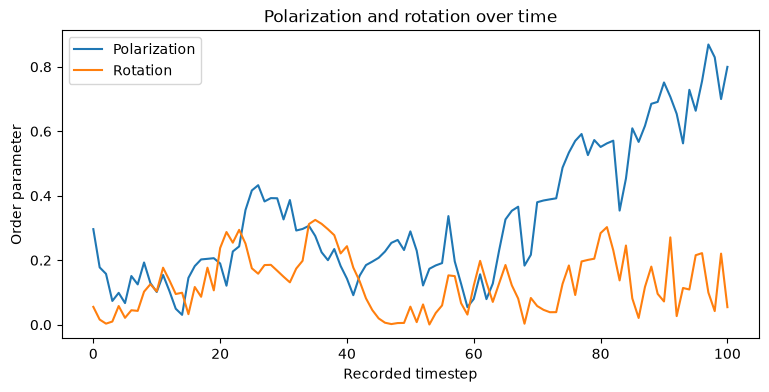

In [10]:

import matplotlib.pyplot as plt

model_data[["Polarization", "Rotation"]].plot(
    figsize=(9, 4)
)

plt.xlabel("Recorded timestep")
plt.ylabel("Order parameter")
plt.title("Polarization and rotation over time")
plt.show()


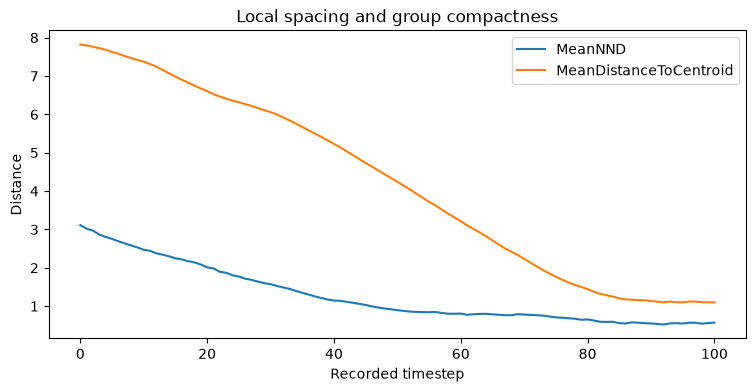

In [11]:

model_data[
    ["MeanNND", "MeanDistanceToCentroid"]
].plot(
    figsize=(9, 4)
)

plt.xlabel("Recorded timestep")
plt.ylabel("Distance")
plt.title("Local spacing and group compactness")
plt.show()



# 7. PyVista — 3D visualization of the 2D physics

The model remains 2D.

For visualization:

\[
(x,y)\rightarrow(x,y,0)
\]

and

\[
(d_x,d_y)\rightarrow(d_x,d_y,0)
\]

This cell does not alter the simulation.


In [12]:

def get_pyvista_state(model):
    """Convert the current 2D fish state into 3D arrays for visualization."""

    positions_2d = np.array([
        fish.position
        for fish in model.agents
    ])

    directions_2d = np.array([
        fish.direction
        for fish in model.agents
    ])

    # Add z = 0
    positions_3d = np.column_stack([
        positions_2d,
        np.zeros(len(positions_2d)),
    ])

    directions_3d = np.column_stack([
        directions_2d,
        np.zeros(len(directions_2d)),
    ])

    return positions_3d, directions_3d



# 8. Next phase — local light controls speed

Do **not** give the shiner the gradient direction.

The next environmental rule is only:

\[
L_i = L(p_i)
\]

\[
s_i = s_{\min} + L_i(s_{\max}-s_{\min})
\]

So:

- dark region → slower
- bright region → faster

The social rules still determine direction.

This is kept separate from the V1 schooling model so we can first validate the social dynamics.


In [14]:

def speed_from_light(light_value, min_speed=0.2, max_speed=5.0):
    """Paper-inspired local light-dependent speed rule."""

    light_value = np.clip(light_value, 0.0, 1.0)

    return (
        min_speed
        + light_value * (max_speed - min_speed)
    )


In [15]:

class SimpleVerticalLightField:
    """
    Minimal test environment.

    0 = dark at the bottom
    1 = bright at the top

    This is only a simple development field.
    The moving noisy light field can be added later.
    """

    def __init__(self, height):
        self.height = float(height)

    def value(self, position):
        return np.clip(
            position[1] / self.height,
            0.0,
            1.0,
        )



# 9. Historical progression from `past_repo`

The cells below are **reference only**.

They show how the project evolved before the integrated model above.

Do not run these after the final class definitions unless you intentionally want to redefine the classes.


## Past Phase 1A: one moving fish

In [16]:

# REFERENCE ONLY — simplified from SingleFish_ContinuousSpace.ipynb

# class GoldenShiners(ContinuousSpaceAgent):
#
#     def __init__(self, model, space, position=(0, 0), speed=1.0):
#         super().__init__(space, model)
#
#         self.position = np.array(position, dtype=float)
#         self.speed = speed
#
#         angle = self.model.rng.uniform(0, 2 * np.pi)
#
#         self.direction = np.array([
#             np.cos(angle),
#             np.sin(angle),
#         ])
#
#     def move(self):
#         new_position = (
#             self.position
#             + self.direction * self.speed
#         )
#
#         self.bounce(new_position)
#         self.position = new_position
#
#     def bounce(self, position):
#         for axis, (minimum, maximum) in enumerate(self.model.bounds):
#
#             if position[axis] < minimum:
#                 position[axis] = 2 * minimum - position[axis]
#                 self.direction[axis] *= -1
#
#             elif position[axis] > maximum:
#                 position[axis] = 2 * maximum - position[axis]
#                 self.direction[axis] *= -1


## Past Phase 1B: neighbour detection

In [21]:

# REFERENCE ONLY — simplified from Couzin_Parameters.ipynb

# def get_neighbors(self):
#
#     neighbors = []
#
#     for other_fish in self.model.agents:
#
#         if other_fish is self:
#             continue
#
#         displacement = (
#             other_fish.position
#             - self.position
#         )
#
#         distance = np.linalg.norm(displacement)
#
#         if distance <= self.model.attraction_radius:
#
#             neighbors.append(
#                 (
#                     other_fish,
#                     displacement,
#                     distance,
#                 )
#             )
#
#     return neighbors


## Past Maria branch: repulsion + attraction

In [18]:

# REFERENCE ONLY — from Couzin_Parameters_maria_attraction.ipynb

# def repulsion(self, neighbors):
#
#     repel = np.zeros(2)
#
#     for _, displacement, distance in neighbors:
#
#         if distance < self.model.repulsion_radius:
#
#             if distance == 0:
#                 continue
#
#             direction_neighbor = displacement / distance
#             repel -= direction_neighbor
#
#     magnitude = np.linalg.norm(repel)
#
#     if magnitude == 0:
#         return None
#
#     return repel / magnitude
#
#
# def attraction(self, neighbors):
#
#     attract = np.zeros(2)
#
#     for _, displacement, distance in neighbors:
#
#         if (
#             self.model.orientation_radius
#             <= distance
#             <= self.model.attraction_radius
#         ):
#             attract += displacement / distance
#
#     magnitude = np.linalg.norm(attract)
#
#     return (
#         attract / magnitude
#         if magnitude > 0
#         else None
#     )


## Past `Couzin.py`: synchronous update

In [19]:

# REFERENCE ONLY — key structure from past_repo/Couzin.py

# def decide(self):
#
#     neighbors = self.get_neighbors()
#     repel = self.repulsion(neighbors)
#
#     if repel is not None:
#         self.next_direction = repel
#     else:
#         self.next_direction = self.direction.copy()
#
#     movement = (
#         self.next_direction
#         * self.speed
#         * self.model.dt
#     )
#
#     self.next_position = (
#         self.position
#         + movement
#     )
#
#
# def advance(self):
#
#     self.direction = self.next_direction.copy()
#     self.position = self.next_position.copy()
#
#
# # Model:
# def step(self):
#
#     self.agents.do("decide")
#     self.agents.do("advance")


## Past `paper_rules.py`: canonical three-zone logic

In [20]:

# REFERENCE ONLY — concept preserved from past_repo/paper_rules.py

# if there is a repulsion neighbour:
#     desired_direction = repulsion
#
# else:
#     orientation = sum(neighbour headings)
#     attraction = sum(unit vectors toward farther neighbours)
#
#     desired_direction = orientation + attraction
#
# This is the logic implemented cleanly in GoldenShiners.social_direction().



# 10. Current project boundary

### Included now
- 2D dynamics
- repulsion
- orientation
- attraction
- synchronous updates
- reflecting walls
- DataCollector V1
- PyVista coordinate conversion

### Intentionally not included yet
- direct gradient sensing
- social speed regulation
- PCA
- true 3D dynamics
- separate cohesion force
- complex ecology / births / deaths / predators
- moving noisy light experiment

Those can be added after the basic schooling model is validated.
